# Revisión Ingeniare · Umbral en validación y Figura 3 a 300 dpi

Responde a dos observaciones de la revisión:

1. **El umbral de operación debe elegirse en validación, no en prueba.** En `Zona_Binario_ROC_Real.ipynb` el 0,35 salió de un barrido sobre las probabilidades del conjunto de **prueba**. Este cuaderno lo rehace con validación.
2. **La Figura 3 debe exportarse a 300 dpi.** La anterior se guardó a 160 dpi.

Además imprime las versiones de las librerías para la Tabla 1.

**Regla de umbral, fijada antes de mirar el test.** Con las probabilidades de **validación** de las tres semillas agrupadas, se elige el **mayor umbral que alcanza una sensibilidad ≥ 0,70**. Ese umbral único se aplica después al conjunto de prueba. Como referencia también se informa el criterio de Youden en validación y el umbral por defecto (0,50).

> No cambies `OBJETIVO_SENS` después de ver los resultados del test. Si lo cambias, el problema que señaló el revisor vuelve a aparecer.

**Tiempo:** si en `notebooks/` están `tmp_zona_42.pt`, `tmp_zona_123.pt` y `tmp_zona_7.pt` (guardados por `Zona_Binario_ROC_Real.ipynb`), tarda unos minutos. Si no están, reentrena las tres semillas con el mismo código (45 min a 1,5 h en MPS) y entonces **todas** las cifras del binario deben tomarse de esta ejecución.

## 1 · Configuración y versiones (para la Tabla 1)

In [1]:
import os, json, platform, random
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import transformers, sklearn, matplotlib
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
import matplotlib.pyplot as plt

DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
MODELO = 'PlanTL-GOB-ES/roberta-base-biomedical-clinical-es'; MODELO_ALT = 'BSC-LT/roberta-base-biomedical-clinical-es'
MAX_LENGTH = 256; LR = 3e-5; EPOCHS = 15; PATIENCE = 4; BATCH = 16
SEEDS = [42, 123, 7]; SPLIT_SEED = 42
OBJETIVO_SENS = 0.70          # regla declarada ANTES de ver el test. No modificar.

VERSIONES = {
    'python': platform.python_version(), 'torch': torch.__version__,
    'transformers': transformers.__version__, 'scikit-learn': sklearn.__version__,
    'numpy': np.__version__, 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__,
    'sistema': f"{platform.system()} {platform.release()} ({platform.machine()})", 'dispositivo': DEVICE,
}
if DEVICE == 'cuda': VERSIONES['gpu'] = torch.cuda.get_device_name(0)
for k, v in VERSIONES.items(): print(f"{k:13s} {v}")

python        3.11.9
torch         2.12.0
transformers  5.10.2
scikit-learn  1.9.0
numpy         2.4.6
pandas        3.0.3
matplotlib    3.10.9
sistema       Darwin 25.6.0 (arm64)
dispositivo   mps


## 2 · Datos y partición fija (idéntica al resto de los experimentos)

In [2]:
df = pd.read_csv('../data/processed/dataset_clean.csv', encoding='utf-8')
X = df['auditor_input'].values; y7 = df['BI-RADS'].values
Xtv, Xte, y7tv, y7te = train_test_split(X, y7, test_size=0.15, random_state=SPLIT_SEED, stratify=y7)
Xtr, Xva, y7tr, y7va = train_test_split(Xtv, y7tv, test_size=0.176, random_state=SPLIT_SEED, stratify=y7tv)
z = lambda v: (np.asarray(v) >= 4).astype(int)
ytr, yva, yte = z(y7tr), z(y7va), z(y7te)
print(f"Train {len(Xtr)} (riesgo {ytr.sum()}) | Val {len(Xva)} (riesgo {yva.sum()}) | Test {len(Xte)} (riesgo {yte.sum()})")

Train 3051 (riesgo 51) | Val 652 (riesgo 11) | Test 654 (riesgo 11)


## 3 · Dataset, modelo y aumentación (copia exacta de `Zona_Binario_ROC_Real.ipynb`)

In [3]:
try: TOK = AutoTokenizer.from_pretrained(MODELO)
except Exception: MODELO = MODELO_ALT; TOK = AutoTokenizer.from_pretrained(MODELO)

class DS(Dataset):
    def __init__(self, t, l): self.t = list(t); self.l = list(l)
    def __len__(self): return len(self.t)
    def __getitem__(self, i):
        e = TOK(str(self.t[i]), truncation=True, padding='max_length', max_length=MAX_LENGTH,
                return_tensors='pt', return_token_type_ids=False)
        return {'input_ids': e['input_ids'].squeeze(0), 'attention_mask': e['attention_mask'].squeeze(0),
                'labels': torch.tensor(self.l[i], dtype=torch.long)}

class ZonaRoBERTa(nn.Module):
    def __init__(self, m, dp=0.3):
        super().__init__(); self.enc = AutoModel.from_pretrained(m)
        self.dp = nn.Dropout(dp); self.cl = nn.Linear(self.enc.config.hidden_size, 2)
    def forward(self, ids, mask):
        return self.cl(self.dp(self.enc(input_ids=ids, attention_mask=mask).last_hidden_state[:, 0, :]))

def aumentar(t):
    V = [('bordes irregulares','márgenes irregulares'),('bordes espiculados','márgenes espiculados'),
         ('bordes mal definidos','límites imprecisos'),('imagen nodular','nódulo'),('nódulo','imagen nodular'),
         ('lesión nodular','nódulo'),('heterogéneamente densas','de densidad heterogénea'),
         ('muy densas','extremadamente densas'),('calcificaciones sospechosas','depósitos cálcicos sospechosos'),
         ('microcalcificaciones','calcificaciones puntiformes agrupadas'),('mama derecha','hemimama derecha'),
         ('mama izquierda','hemimama izquierda'),('se visualiza','se observa'),('se observa','se visualiza'),
         ('se evidencia','se observa')]
    s = t
    for o, r in random.sample(V, min(3, len(V))):
        if o in s: s = s.replace(o, r, 1)
    return s

def entrenar_zona(seed):
    # Igual que en Zona_Binario_ROC_Real.ipynb. Guarda tmp_zona_{seed}.pt
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if DEVICE == 'mps': torch.mps.manual_seed(seed)
    mask = (ytr == 1); ta, la = [], []
    for txt in Xtr[mask]:
        for _ in range(3): ta.append(aumentar(txt)); la.append(1)
    Xa = np.concatenate([Xtr, np.array(ta)]); ya = np.concatenate([ytr, np.array(la)])
    idx = np.random.RandomState(seed).permutation(len(Xa)); Xa, ya = Xa[idx], ya[idx]
    tl = DataLoader(DS(Xa, ya), batch_size=BATCH, shuffle=True); vl = DataLoader(DS(Xva, yva), batch_size=BATCH)
    model = ZonaRoBERTa(MODELO).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    sch = get_linear_schedule_with_warmup(opt, 0, len(tl) * EPOCHS)
    pw = compute_class_weight('balanced', classes=np.array([0, 1]), y=ya)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(pw, dtype=torch.float32).to(DEVICE))
    def ep(loader, train=True):
        model.train() if train else model.eval(); P = []; R = []
        with torch.set_grad_enabled(train):
            for b in loader:
                ids = b['input_ids'].to(DEVICE); mk = b['attention_mask'].to(DEVICE); lb = b['labels'].to(DEVICE)
                if train: opt.zero_grad()
                lo = model(ids, mk); loss = crit(lo, lb)
                if train: loss.backward(); opt.step(); sch.step()
                P.extend(torch.softmax(lo, 1)[:, 1].detach().cpu().numpy()); R.extend(lb.cpu().numpy())
        try: return roc_auc_score(R, P)
        except Exception: return 0.5
    mejor, sin = 0, 0; ruta = f'tmp_zona_{seed}.pt'
    for e in range(1, EPOCHS + 1):
        _ = ep(tl, True); va = ep(vl, False)
        if va > mejor: mejor, sin = va, 0; torch.save(model.state_dict(), ruta)
        else: sin += 1
        if sin >= PATIENCE: break
    return ruta
print("Listo.")

Listo.


## 4 · Modelos de las tres semillas (reutiliza los `.pt` si existen)

In [4]:
REENTRENADO = {}
for s in SEEDS:
    ruta = f'tmp_zona_{s}.pt'
    if os.path.exists(ruta):
        print(f"semilla {s}: uso {ruta} (no se reentrena)"); REENTRENADO[s] = False
    else:
        print(f"semilla {s}: no existe {ruta}, entrenando ...", flush=True); entrenar_zona(s); REENTRENADO[s] = True
if any(REENTRENADO.values()):
    print("\nAVISO: hubo reentrenamiento. Usa en el manuscrito SOLO las cifras de este cuaderno (AUC incluido).")

semilla 42: uso tmp_zona_42.pt (no se reentrena)
semilla 123: uso tmp_zona_123.pt (no se reentrena)
semilla 7: uso tmp_zona_7.pt (no se reentrena)


## 5 · Probabilidades en validación y en prueba

In [5]:
def probs(model, Xs, ys):
    dl = DataLoader(DS(Xs, ys), batch_size=BATCH); P = []
    with torch.no_grad():
        for b in dl:
            ids = b['input_ids'].to(DEVICE); mk = b['attention_mask'].to(DEVICE)
            P.extend(torch.softmax(model(ids, mk).float(), 1)[:, 1].cpu().numpy())
    return np.array(P)

PV, PT = {}, {}
for s in SEEDS:
    m = ZonaRoBERTa(MODELO).to(DEVICE)
    m.load_state_dict(torch.load(f'tmp_zona_{s}.pt', map_location=DEVICE)); m.eval()
    PV[s] = probs(m, Xva, yva); PT[s] = probs(m, Xte, yte)
    print(f"semilla {s}: AUC val {roc_auc_score(yva, PV[s]):.4f} | AUC test {roc_auc_score(yte, PT[s]):.4f}")
auc_t = [roc_auc_score(yte, PT[s]) for s in SEEDS]
print(f"\nAUC-ROC test: {np.mean(auc_t):.4f} ± {np.std(auc_t):.4f}   (manuscrito actual: 0,9161 ± 0,0220)")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: PlanTL-GOB-ES/roberta-base-biomedical-clinical-es
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.decoder.weight    | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.decoder.bias      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


semilla 42: AUC val 0.9521 | AUC test 0.9114


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: PlanTL-GOB-ES/roberta-base-biomedical-clinical-es
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.decoder.weight    | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.decoder.bias      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


semilla 123: AUC val 0.9687 | AUC test 0.9451


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: PlanTL-GOB-ES/roberta-base-biomedical-clinical-es
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.decoder.weight    | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.decoder.bias      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


semilla 7: AUC val 0.9687 | AUC test 0.8918

AUC-ROC test: 0.9161 ± 0.0220   (manuscrito actual: 0,9161 ± 0,0220)


## 6 · Elección del umbral **en validación**

In [6]:
def conteos(y, p, thr):
    yp = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, yp, labels=[0, 1]).ravel()
    return tp, fn, fp, tn

yv_all = np.concatenate([yva] * len(SEEDS)); pv_all = np.concatenate([PV[s] for s in SEEDS])
grid = np.round(np.arange(0.01, 1.00, 0.01), 2)

# Regla principal: mayor umbral con sensibilidad >= OBJETIVO_SENS en validación
validos = [t for t in grid if (lambda c: c[0] / (c[0] + c[1]))(conteos(yv_all, pv_all, t)) >= OBJETIVO_SENS]
THR = max(validos) if validos else 0.50
# Referencia: Youden en validación
fpr, tpr, th = roc_curve(yv_all, pv_all)
THR_YOUDEN = float(np.clip(th[np.argmax(tpr - fpr)], 0.01, 0.99))

tp, fn, fp, tn = conteos(yv_all, pv_all, THR)
print(f"Umbral elegido en VALIDACIÓN (sens >= {OBJETIVO_SENS}): {THR:.2f}")
print(f"   en validación: sens {tp/(tp+fn):.3f} ({tp}/{tp+fn}) | espec {tn/(tn+fp):.3f}")
print(f"Umbral de Youden en validación (referencia): {THR_YOUDEN:.3f}")

Umbral elegido en VALIDACIÓN (sens >= 0.7): 0.14
   en validación: sens 0.727 (24/33) | espec 0.942
Umbral de Youden en validación (referencia): 0.095


## 7 · Resultado en el conjunto de **prueba** con el umbral de validación

In [7]:
yt_all = np.concatenate([yte] * len(SEEDS)); pt_all = np.concatenate([PT[s] for s in SEEDS])
RES = {}
print(f"{'Umbral':24s} | {'Sens agrup.':>12s} | {'Espec agrup.':>12s} | {'Sens media ± DE':>16s} | {'Espec media ± DE':>17s} | TP/riesgo | FP")
for nombre, t in [(f'Validación ({THR:.2f})', THR), (f'Youden val ({THR_YOUDEN:.2f})', THR_YOUDEN), ('Por defecto (0.50)', 0.50)]:
    tp, fn, fp, tn = conteos(yt_all, pt_all, t)
    se_s = [(lambda c: c[0]/(c[0]+c[1]))(conteos(yte, PT[s], t)) for s in SEEDS]
    es_s = [(lambda c: c[3]/(c[3]+c[2]))(conteos(yte, PT[s], t)) for s in SEEDS]
    RES[nombre] = dict(umbral=round(float(t), 3), sens_agrupada=tp/(tp+fn), espec_agrupada=tn/(tn+fp),
                       sens_media=float(np.mean(se_s)), sens_de=float(np.std(se_s)),
                       espec_media=float(np.mean(es_s)), espec_de=float(np.std(es_s)),
                       tp=int(tp), riesgo=int(tp+fn), fp_total=int(fp), fp_por_semilla=float(fp/len(SEEDS)))
    print(f"{nombre:24s} | {tp/(tp+fn):12.3f} | {tn/(tn+fp):12.3f} | {np.mean(se_s):.3f} ± {np.std(se_s):.3f}  | "
          f"{np.mean(es_s):.3f} ± {np.std(es_s):.3f}   | {tp:3d}/{tp+fn:<5d} | {fp}")
print("\n'Agrupada' = las 3 semillas juntas (33 casos de riesgo). FP por semilla = FP / 3.")

Umbral                   |  Sens agrup. | Espec agrup. |  Sens media ± DE |  Espec media ± DE | TP/riesgo | FP
Validación (0.14)        |        0.727 |        0.947 | 0.727 ± 0.129  | 0.947 ± 0.058   |  24/33    | 102
Youden val (0.10)        |        0.727 |        0.922 | 0.727 ± 0.129  | 0.922 ± 0.088   |  24/33    | 151
Por defecto (0.50)       |        0.667 |        0.984 | 0.667 ± 0.043  | 0.984 ± 0.013   |  22/33    | 30

'Agrupada' = las 3 semillas juntas (33 casos de riesgo). FP por semilla = FP / 3.


## 8 · Figura 3 a 300 dpi (PNG, TIFF y PDF)

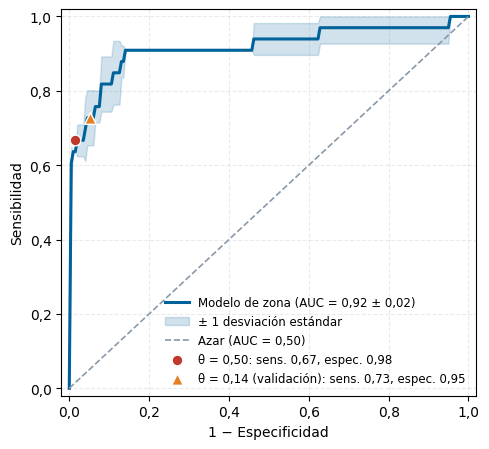

PNG: (1468, 1349) px | dpi: (299.9994, 299.9994)


In [8]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
from matplotlib.ticker import FuncFormatter
n2 = lambda x: f'{x:.2f}'.replace('.', ',')
fgrid = np.linspace(0, 1, 200); tprs = []
for s in SEEDS:
    f, t, _ = roc_curve(yte, PT[s]); ti = np.interp(fgrid, f, t); ti[0] = 0.0; tprs.append(ti)
tm, tsd = np.mean(tprs, 0), np.std(tprs, 0)
rp = RES['Por defecto (0.50)']; rv = RES[f'Validación ({THR:.2f})']

fig, ax = plt.subplots(figsize=(5.0, 4.6))
ax.plot(fgrid, tm, color='#00629B', lw=2.2, label=f'Modelo de zona (AUC = {n2(np.mean(auc_t))} ± {n2(np.std(auc_t))})')
ax.fill_between(fgrid, np.clip(tm - tsd, 0, 1), np.clip(tm + tsd, 0, 1), alpha=0.18, color='#00629B', label='± 1 desviación estándar')
ax.plot([0, 1], [0, 1], '--', color='#8A99A8', lw=1.2, label='Azar (AUC = 0,50)')
ax.scatter([1 - rp['espec_agrupada']], [rp['sens_agrupada']], marker='o', color='#C0392B', s=60, zorder=6, edgecolor='white', lw=1.0,
           label=f"θ = 0,50: sens. {n2(rp['sens_agrupada'])}, espec. {n2(rp['espec_agrupada'])}")
ax.scatter([1 - rv['espec_agrupada']], [rv['sens_agrupada']], marker='^', color='#E67E22', s=70, zorder=6, edgecolor='white', lw=1.0,
           label=f"θ = {n2(THR)} (validación): sens. {n2(rv['sens_agrupada'])}, espec. {n2(rv['espec_agrupada'])}")
ax.set_xlabel('1 − Especificidad'); ax.set_ylabel('Sensibilidad')
fmt = FuncFormatter(lambda v, _: f'{v:.1f}'.replace('.', ',')); ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.legend(loc='lower right', fontsize=8.5, frameon=False)
ax.grid(alpha=0.25, linestyle='--'); ax.set_axisbelow(True); fig.tight_layout()
os.makedirs('../results/figures', exist_ok=True)
for ext in ['png', 'tiff', 'pdf']:
    fig.savefig(f'../results/figures/Figura3_ROC_zona_300dpi.{ext}', dpi=300, bbox_inches='tight')
plt.show()
from PIL import Image
im = Image.open('../results/figures/Figura3_ROC_zona_300dpi.png'); print("PNG:", im.size, "px | dpi:", im.info.get('dpi'))

## 9 · Guardar todas las cifras

In [9]:
salida = {'versiones': VERSIONES, 'semillas': SEEDS, 'reentrenado': REENTRENADO, 'objetivo_sens_validacion': OBJETIVO_SENS,
          'auc_test_por_semilla': [round(a, 4) for a in auc_t],
          'auc_test_media': round(float(np.mean(auc_t)), 4), 'auc_test_de': round(float(np.std(auc_t)), 4),
          'umbral_validacion': THR, 'umbral_youden_validacion': round(THR_YOUDEN, 3),
          'resultados_test': {k: {kk: (round(vv, 4) if isinstance(vv, float) else vv) for kk, vv in v.items()} for k, v in RES.items()}}
os.makedirs('../results/metrics', exist_ok=True)
json.dump(salida, open('../results/metrics/revision_ingeniare_umbral.json', 'w'), indent=2, ensure_ascii=False)
print(json.dumps(salida, indent=2, ensure_ascii=False))

{
  "versiones": {
    "python": "3.11.9",
    "torch": "2.12.0",
    "transformers": "5.10.2",
    "scikit-learn": "1.9.0",
    "numpy": "2.4.6",
    "pandas": "3.0.3",
    "matplotlib": "3.10.9",
    "sistema": "Darwin 25.6.0 (arm64)",
    "dispositivo": "mps"
  },
  "semillas": [
    42,
    123,
    7
  ],
  "reentrenado": {
    "42": false,
    "123": false,
    "7": false
  },
  "objetivo_sens_validacion": 0.7,
  "auc_test_por_semilla": [
    0.9114,
    0.9451,
    0.8918
  ],
  "auc_test_media": 0.9161,
  "auc_test_de": 0.022,
  "umbral_validacion": 0.14,
  "umbral_youden_validacion": 0.095,
  "resultados_test": {
    "Validación (0.14)": {
      "umbral": 0.14,
      "sens_agrupada": 0.7273,
      "espec_agrupada": 0.9471,
      "sens_media": 0.7273,
      "sens_de": 0.1286,
      "espec_media": 0.9471,
      "espec_de": 0.0575,
      "tp": 24,
      "riesgo": 33,
      "fp_total": 102,
      "fp_por_semilla": 34.0
    },
    "Youden val (0.10)": {
      "umbral": 0.095,
     

## 10 · Qué copiar al manuscrito

- **Tabla 1, hardware y software:** las versiones de la celda 1.
- **Métricas de evaluación:** "El umbral de operación θ se eligió en el conjunto de validación como el mayor valor que alcanza una sensibilidad de al menos 0,70 con las probabilidades de las tres semillas, y se aplicó sin cambios al conjunto de prueba." Escribe el valor de `THR`.
- **Resumen, Tabla 4, Resultados, Discusión y Conclusiones:** reemplaza sensibilidad 0,70 y especificidad 0,98 por la fila *Validación* de la celda 7 (media ± DE por semilla). Las falsas alarmas por semilla salen de `fp_por_semilla`.
- **Figura 3:** `results/figures/Figura3_ROC_zona_300dpi.tiff` (o `.png`).
- Envía `revision_ingeniare_umbral.json` a Claude para actualizar el texto.